In [2]:
import numpy as np
rng = np.random.default_rng(42)                               # seed cố định → ai chạy cũng ra cùng dãy
close = 100 * np.cumprod(1 + rng.normal(0, 0.01, 250))       # 250 ngày giá đóng cửa giả lập
print(close)

[100.30471708  99.26156396 100.00647356 100.94709916  98.97758574
  97.6887199   97.81360555  97.50427727  97.48789542  96.65628085
  97.50627423  98.26467016  98.32955501  99.43796627  99.90284806
  99.04439041  99.40961738  98.45639585  99.32128636  99.2716993
  99.08818329  98.41346258  99.61660784  99.46267081  99.03664452
  98.68790327  99.21322804  99.5757969   99.98677868 100.41754273
 102.56813262 102.15128033 101.62801782 100.80099673 101.42191013
 102.56693539 102.45006297 101.58932213 100.75173726 101.40722079
 102.16093419 102.71582567 102.03224187 102.26912128 102.38845483
 102.6123667  103.5065604  103.73799646 104.44228779 104.51286891
 104.81503589 105.47672087 103.9397607  103.6074952  103.12015387
 102.46134205 102.17942761 103.70695008 102.80902304 103.80450056
 102.057606   101.71583035 101.88137598 102.47862736 103.2074826
 104.02627631 103.6635106  103.1842205  104.06951623 103.87042674
 102.54536591 101.38323239 100.45106194 100.95046519 101.09424463
 101.7922855

In [3]:
def returns(p):
    return p[1:] / p[:-1] - 1

In [4]:
r = returns(close)
print(r)

[-1.03998411e-02  7.50451196e-03  9.40564716e-03 -1.95103519e-02
 -1.30217951e-02  1.27840403e-03 -3.16242592e-03 -1.68011575e-04
 -8.53043928e-03  8.79397975e-03  7.77791935e-03  6.60306976e-04
  1.12724121e-02  4.67509342e-03 -8.59292463e-03  3.68750784e-03
 -9.58882601e-03  8.78450301e-03 -4.99259110e-04 -1.84862364e-03
 -6.80929544e-03  1.22254134e-02 -1.54529482e-03 -4.28327822e-03
 -3.52133550e-03  5.32309186e-03  3.65444064e-03  4.12732612e-03
  4.30821003e-03  2.14164760e-02 -4.06415016e-03 -5.12242729e-03
 -8.13772728e-03  6.15979423e-03  1.12897229e-02 -1.13947458e-03
 -8.40156477e-03 -8.24481216e-03  6.50592788e-03  7.43254171e-03
  5.43154268e-03 -6.65509707e-03  2.32161323e-03  1.16685809e-03
  2.18688597e-03  8.71428778e-03  2.23595549e-03  6.78913563e-03
  6.75790695e-04  2.89119399e-03  6.31288226e-03 -1.45715582e-02
 -3.19671216e-03 -4.70372654e-03 -6.38877848e-03 -2.75142251e-03
  1.49494131e-02 -8.65831116e-03  9.68278355e-03 -1.68286977e-02
 -3.34885030e-03  1.62753

In [5]:
mask = r > 0.01          # True/False, 249 phần tử
big_days = r[mask]       # chỉ các lợi suất > 1%
count = mask.sum()       # số True
avg = big_days.mean()


In [6]:
signal = np.where(r > 0,1,-1)
print(signal)

[-1  1  1 -1 -1  1 -1 -1 -1  1  1  1  1  1 -1  1 -1  1 -1 -1 -1  1 -1 -1
 -1  1  1  1  1  1 -1 -1 -1  1  1 -1 -1 -1  1  1  1 -1  1  1  1  1  1  1
  1  1  1 -1 -1 -1 -1 -1  1 -1  1 -1 -1  1  1  1  1 -1 -1  1 -1 -1 -1 -1
  1  1  1 -1  1  1 -1  1 -1 -1 -1 -1  1 -1  1  1  1  1 -1 -1 -1 -1 -1 -1
 -1  1 -1 -1  1 -1  1 -1 -1 -1 -1  1 -1  1  1 -1 -1  1 -1  1  1  1 -1 -1
  1  1  1  1  1  1 -1 -1 -1 -1 -1  1 -1 -1 -1  1  1  1  1  1 -1 -1  1 -1
 -1 -1 -1  1  1 -1 -1 -1 -1 -1  1  1  1 -1 -1 -1 -1  1 -1  1 -1  1  1 -1
 -1 -1  1 -1 -1 -1  1  1  1 -1  1  1  1 -1  1  1  1  1 -1 -1  1  1 -1 -1
  1 -1 -1  1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1 -1 -1  1 -1  1 -1 -1  1  1
  1 -1 -1 -1  1  1 -1  1  1  1  1 -1 -1 -1 -1  1  1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1  1 -1 -1  1  1 -1]


In [7]:
strat_ret = r[1:] * signal[:-1]
print(strat_ret)
pnl = np.prod(strat_ret)
print(f"pnl hiện tại là {pnl}")

[-7.50451196e-03  9.40564716e-03 -1.95103519e-02  1.30217951e-02
 -1.27840403e-03 -3.16242592e-03  1.68011575e-04  8.53043928e-03
 -8.79397975e-03  7.77791935e-03  6.60306976e-04  1.12724121e-02
  4.67509342e-03 -8.59292463e-03 -3.68750784e-03 -9.58882601e-03
 -8.78450301e-03 -4.99259110e-04  1.84862364e-03  6.80929544e-03
 -1.22254134e-02 -1.54529482e-03  4.28327822e-03  3.52133550e-03
 -5.32309186e-03  3.65444064e-03  4.12732612e-03  4.30821003e-03
  2.14164760e-02 -4.06415016e-03  5.12242729e-03  8.13772728e-03
 -6.15979423e-03  1.12897229e-02 -1.13947458e-03  8.40156477e-03
  8.24481216e-03 -6.50592788e-03  7.43254171e-03  5.43154268e-03
 -6.65509707e-03 -2.32161323e-03  1.16685809e-03  2.18688597e-03
  8.71428778e-03  2.23595549e-03  6.78913563e-03  6.75790695e-04
  2.89119399e-03  6.31288226e-03 -1.45715582e-02  3.19671216e-03
  4.70372654e-03  6.38877848e-03  2.75142251e-03 -1.49494131e-02
 -8.65831116e-03 -9.68278355e-03 -1.68286977e-02  3.34885030e-03
 -1.62753065e-03  5.86222

In [8]:
def compound(x):
    return np.prod(1 + x) - 1

In [9]:
x = np.array([-0.0098039, -0.0297030, -0.0096154])  
print(compound(x))
assert np.isclose(compound(x), -0.04845, atol=1e-4)

-0.04845402016692113


In [10]:
rng = np.random.default_rng(42)
big = 100 + np.cumsum(rng.normal(0, 0.5, 1_000_000))

In [11]:
def returns_loop(p):
    result = []
    for i in range(1, len(p)):
        result.append(p[i] / p[i-1] - 1)
    return np.array(result)

In [12]:
def returns(p):
    return p[1:] / p[:-1] - 1

In [13]:
%timeit returns_loop(big)

260 ms ± 5.33 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [14]:
%timeit returns(big)

4.37 ms ± 380 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [15]:
assert np.allclose(returns_loop(big), returns(big))

In [16]:
rng = np.random.default_rng(7)
start = np.array([1.08, 150.0, 4500.0])            
steps = rng.normal(0, 0.01, size=(250, 3))
prices = start * np.cumprod(1 + steps, axis=0)     
print(prices)

[[1.08001329e+00 1.50448118e+02 4.48766380e+03]
 [1.07039478e+00 1.49764075e+02 4.44316203e+03]
 [1.07103855e+00 1.51771236e+02 4.42129250e+03]
 [1.06439302e+00 1.52514675e+02 4.43707152e+03]
 [1.06551505e+00 1.51095575e+02 4.43577359e+03]
 [1.07292361e+00 1.49064526e+02 4.41547480e+03]
 [1.05252494e+00 1.47142283e+02 4.33415345e+03]
 [1.05005055e+00 1.45277333e+02 4.34591046e+03]
 [1.05169651e+00 1.45005765e+02 4.23653434e+03]
 [1.04603110e+00 1.44935435e+02 4.24133471e+03]
 [1.03002540e+00 1.44243002e+02 4.19983244e+03]
 [1.02169417e+00 1.45773274e+02 4.16591734e+03]
 [1.02136190e+00 1.47062478e+02 4.14160503e+03]
 [1.02022102e+00 1.47224929e+02 4.14424662e+03]
 [1.00772274e+00 1.47337026e+02 4.20055961e+03]
 [9.92131813e-01 1.48603215e+02 4.20557315e+03]
 [9.85767581e-01 1.51575899e+02 4.23763054e+03]
 [9.73945380e-01 1.51688847e+02 4.26206851e+03]
 [9.72106745e-01 1.52724746e+02 4.25923350e+03]
 [9.78593103e-01 1.54921726e+02 4.23045547e+03]
 [9.80581004e-01 1.54203962e+02 4.235839

In [17]:
prices.shape
print(prices[:,0])

[1.08001329 1.07039478 1.07103855 1.06439302 1.06551505 1.07292361
 1.05252494 1.05005055 1.05169651 1.0460311  1.0300254  1.02169417
 1.0213619  1.02022102 1.00772274 0.99213181 0.98576758 0.97394538
 0.97210674 0.9785931  0.980581   0.9689396  0.97764808 0.96987927
 0.96538708 0.9720425  0.9696105  0.96666598 0.9647589  0.96047941
 0.96024752 0.97035053 0.95782434 0.93832947 0.93986882 0.93400457
 0.93235693 0.93720433 0.93753504 0.92949139 0.93032149 0.91173603
 0.89232911 0.89908171 0.90025907 0.91323817 0.9117782  0.90682823
 0.90115082 0.89976226 0.89351428 0.8935854  0.88126666 0.8753513
 0.88766988 0.88205934 0.88185255 0.88586307 0.8760454  0.87160293
 0.8677579  0.86513842 0.87531684 0.87038381 0.87879561 0.8856629
 0.88162766 0.88922485 0.90593346 0.89063522 0.89052473 0.87173483
 0.86959208 0.85643085 0.84235557 0.84577999 0.83733028 0.8307742
 0.84759871 0.84684021 0.84294311 0.84362635 0.8434452  0.82683948
 0.83786588 0.82998408 0.83038246 0.83707041 0.82834087 0.8374016

In [18]:
norm = prices / prices[0] * 100
assert np.allclose(norm[0], 100)

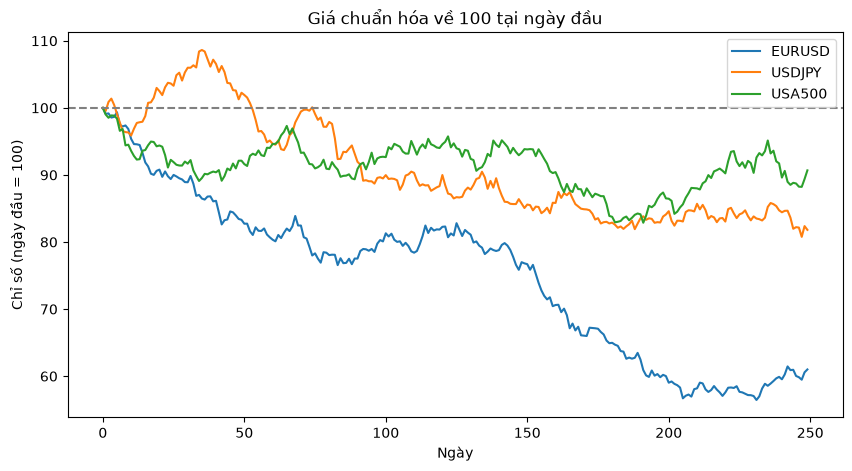

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))                       # khung hình rộng 10, cao 5 (inch)
plt.plot(norm)                                    # norm có shape (250, 3) → mỗi CỘT thành 1 đường
plt.legend(["EURUSD", "USDJPY", "USA500"])        # tên theo đúng thứ tự cột
plt.axhline(100, color="gray", linestyle="--")    # đường mốc 100 = điểm xuất phát
plt.title("Giá chuẩn hóa về 100 tại ngày đầu")
plt.xlabel("Ngày")
plt.ylabel("Chỉ số (ngày đầu = 100)")
plt.show()

In [20]:
ma = np.convolve(close, np.ones(20)/20, mode="same")

# LOOP
out_loop = []
for i in range(len(close)):
    if close[i] > ma[i]:
        out_loop.append(1)
    else:
        out_loop.append(-1)
out_loop = np.array(out_loop)

#VECTOR
signal_vec = np.where(close > ma, 1, -1)

assert np.array_equal(signal_vec, out_loop)
print(len(signal_vec), signal_vec[:10])

250 [1 1 1 1 1 1 1 1 1 1]


In [ ]:
# 1) Bản trung thực và bản gian lận trên close 250 giá
honest = signal[:-1] * r[1:]
cheat  = signal * r
print(len(honest), len(cheat))                 # dự đoán: 248 và 249
print(compound(honest), compound(cheat))       # dự đoán: bản cheat lớn hơn, lớn hơn không đáng kể
print((honest < 0).mean(), (cheat < 0).mean()) # dự đoán: 0.41 và 0

248 249
0.5059303784804492 5.451459982238414
0.4112903225806452 0.0
-0.009999999999999898


In [26]:
# 2) Ca tính tay: tính đáp án bằng tay TRƯỚC, rồi mới điền vào assert
assert np.isclose(compound(np.array([0.10, -0.10])), -0.01)

In [ ]:
# 3) Ô broadcasting
assert np.allclose(norm[0], 100)
print(prices[:, 0:1].shape)                    # dự đoán: 250,1
rel = prices / prices[:, 0:1]
print(rel.shape, rel[:5, 0])                   # dự đoán: 250,3

(250, 1)
(250, 3) [1. 1. 1. 1. 1.]


In [28]:
# 4) Vòng for và phép vector cho ra cùng tín hiệu
assert np.array_equal(signal_vec, out_loop)